# Lab: Fine-Tuning Pre-Trained Models

This notebook contains the starter code provided for the lab (with intentional errors for the debugging exercise).

Follow the lab steps to identify, analyze, and fix the errors, then fine-tune and evaluate the model.

In [2]:
import torch
import numpy as np
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
from transformers import AutoTokenizer, AutoModelForSequenceClassification, TrainingArguments, Trainer
from datasets import load_dataset
from transformers import DataCollatorWithPadding

# Step 1: Load a Pre-Trained Model and Tokenizer
model_checkpoint = "distilbert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(model_checkpoint)
model = AutoModelForSequenceClassification.from_pretrained(model_checkpoint, num_labels=2)

# Step 2: Prepare the Fine-Tuning Dataset (as specified)
train_data = load_dataset("stanfordnlp/imdb", split="train").shuffle(seed=42).select(range(2000))
test_data = load_dataset("stanfordnlp/imdb", split="train").shuffle(seed=42).select(range(500))

def tokenize_function(examples):
    return tokenizer(examples["text"], truncation=True, padding=False)

tokenized_train = train_data.map(tokenize_function, batched=True)
tokenized_test = test_data.map(tokenize_function, batched=True)

# Compute metrics function (required for accuracy, precision, recall, F1)
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)
    precision, recall, f1, _ = precision_recall_fscore_support(labels, predictions, average="binary")
    acc = accuracy_score(labels, predictions)
    return {
        "accuracy": acc,
        "precision": precision,
        "recall": recall,
        "f1": f1,
    }

# Step 3: Fine-Tune the Pre-Trained Model
training_args = TrainingArguments(
    output_dir="./results",
    num_train_epochs=3,
    per_device_train_batch_size=16,
    learning_rate=2e-5,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="accuracy",
    logging_steps=10,
)
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_train,
    eval_dataset=tokenized_test,
    processing_class=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
)

print(trainer.train())

# Step 4: Evaluate and Test the Fine-Tuned Model
results = trainer.evaluate()
print("Test accuracy:", round(results["eval_accuracy"], 3))

metrics = trainer.evaluate()

print("\nFinal evaluation metrics:")
print(f"Loss:      {metrics['eval_loss']:.4f}")
print(f"Accuracy:  {metrics['eval_accuracy']:.2%}")
print(f"Precision: {metrics['eval_precision']:.4f}")
print(f"Recall:    {metrics['eval_recall']:.4f}")
print(f"F1 score:  {metrics['eval_f1']:.4f}")

# Sample inference
test_input = "The movie was absolutely fantastic and I loved it."
test_encoding = tokenizer(test_input, return_tensors="pt")

device = next(model.parameters()).device
test_encoding = {k: v.to(device) for k, v in test_encoding.items()}

with torch.no_grad():
    logits = model(**test_encoding).logits

predicted_class = torch.argmax(logits, dim=1)
print("\nPredicted class:", predicted_class.item())
print("Class meaning:", "Positive" if predicted_class.item() == 1 else "Negative")


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

... (13 outputs left out)

Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1
0.105731,0.097871,3,0.974000,0.971660,0.975610,0.973631


Test accuracy: 0.974


Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1
0.105731,0.097871,3,0.974000,0.971660,0.975610,0.973631



Final evaluation metrics:
Loss:      0.0979
Accuracy:  97.40%
Precision: 0.9717
Recall:    0.9756
F1 score:  0.9736

Predicted class: 1
Class meaning: Positive


## Learning Curves

The plots below show how loss and accuracy change over epochs for the trained model. These are the learning curves for the hyperparameters used in the training run above.


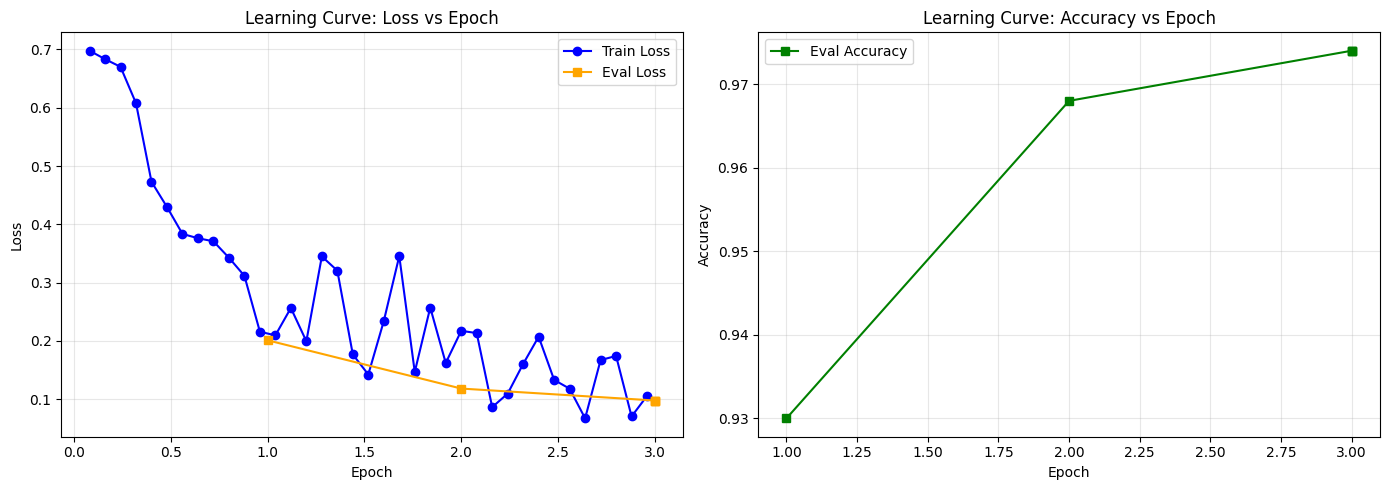

Hyperparameters used in this run:
  Learning rate: 2e-05
  Batch size: 16
  Epochs: 3
  Eval strategy: IntervalStrategy.EPOCH


In [3]:
import matplotlib.pyplot as plt
import pandas as pd

# Extract training history
log_history = trainer.state.log_history
df = pd.DataFrame(log_history)

# Separate train and eval logs
train_logs = df[df["loss"].notna()][["step", "loss", "epoch"]].copy()
eval_logs = df[df["eval_loss"].notna()][["step", "eval_loss", "eval_accuracy", "eval_precision", "eval_recall", "eval_f1", "epoch"]].copy()

# Plot learning curves (loss and accuracy)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Loss curve
if not train_logs.empty:
    axes[0].plot(train_logs["epoch"], train_logs["loss"], "o-", label="Train Loss", color="blue")
if not eval_logs.empty:
    axes[0].plot(eval_logs["epoch"], eval_logs["eval_loss"], "s-", label="Eval Loss", color="orange")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].set_title("Learning Curve: Loss vs Epoch")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Accuracy curve
if not eval_logs.empty and "eval_accuracy" in eval_logs.columns:
    axes[1].plot(eval_logs["epoch"], eval_logs["eval_accuracy"], "s-", label="Eval Accuracy", color="green")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Accuracy")
    axes[1].set_title("Learning Curve: Accuracy vs Epoch")
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("Hyperparameters used in this run:")
print(f"  Learning rate: {training_args.learning_rate}")
print(f"  Batch size: {training_args.per_device_train_batch_size}")
print(f"  Epochs: {training_args.num_train_epochs}")
print(f"  Eval strategy: {training_args.eval_strategy}")


## Comparing Hyperparameters

The following cell trains short runs with different learning rates and plots their learning curves. You can adapt the same pattern for other hyperparameters (batch size, epochs, weight decay, etc.).



Training with learning_rate=1e-05...


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.450443,0.456982,0.884000,0.915929,0.841463,0.877119


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Training with learning_rate=2e-05...


... (5 outputs left out)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.217445,0.219944,0.926000,0.940928,0.906504,0.923395


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

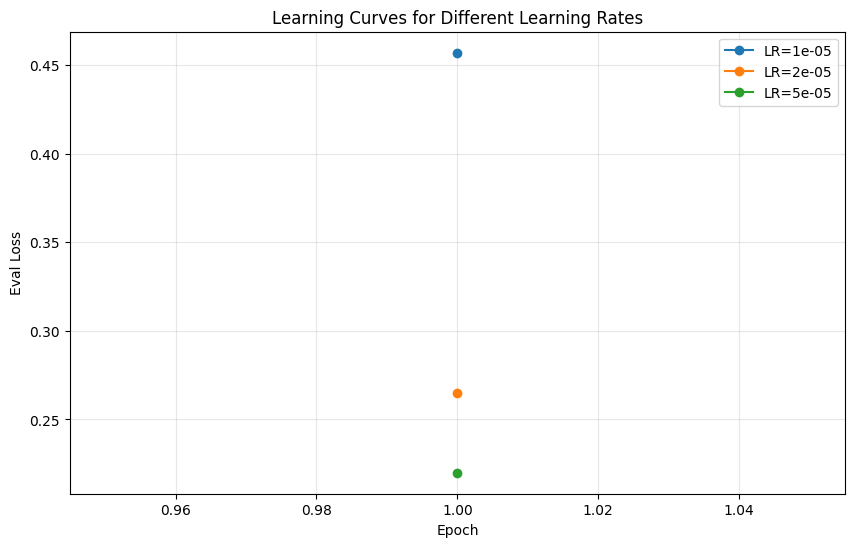


You can extend this pattern to other hyperparameters:
  - per_device_train_batch_size: [8, 16, 32]
  - num_train_epochs: [1, 3, 5]
  - weight_decay: [0.0, 0.01, 0.1]
Note: Each run trains a new model, so use fewer epochs or a smaller subset if compute is limited.


In [4]:
# Example: Learning curves for different learning rates
# (Uses 1 epoch each for speed. Increase epochs for fuller curves.)

def train_with_lr(lr, epochs=1):
    model_lr = AutoModelForSequenceClassification.from_pretrained(model_checkpoint, num_labels=2)
    args_lr = TrainingArguments(
        output_dir=f"./results_lr_{lr}",
        num_train_epochs=epochs,
        per_device_train_batch_size=16,
        learning_rate=lr,
        eval_strategy="epoch",
        logging_steps=10,
        report_to="none",
    )
    trainer_lr = Trainer(
        model=model_lr,
        args=args_lr,
        train_dataset=tokenized_train,
        eval_dataset=tokenized_test,
        processing_class=tokenizer,
        data_collator=data_collator,
        compute_metrics=compute_metrics,
    )
    trainer_lr.train()
    return trainer_lr.state.log_history

learning_rates = [1e-5, 2e-5, 5e-5]
histories = {}
for lr in learning_rates:
    print(f"\nTraining with learning_rate={lr}...")
    histories[lr] = train_with_lr(lr, epochs=1)

# Plot comparison
plt.figure(figsize=(10, 6))
for lr, history in histories.items():
    df_h = pd.DataFrame(history)
    eval_h = df_h[df_h["eval_loss"].notna()]
    if not eval_h.empty:
        plt.plot(eval_h["epoch"], eval_h["eval_loss"], "o-", label=f"LR={lr}")
plt.xlabel("Epoch")
plt.ylabel("Eval Loss")
plt.title("Learning Curves for Different Learning Rates")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

print("\nYou can extend this pattern to other hyperparameters:")
print("  - per_device_train_batch_size: [8, 16, 32]")
print("  - num_train_epochs: [1, 3, 5]")
print("  - weight_decay: [0.0, 0.01, 0.1]")
print("Note: Each run trains a new model, so use fewer epochs or a smaller subset if compute is limited.")


<b>Lab Report: Debugging and Fine-Tuning Process</b>

I began by reviewing the provided script and identified three intentional errors that would prevent successful execution. First, the model was loaded with a misspelled parameter (num_labes instead of num_labels). Second, num_train_epochs was supplied as a string ("3") rather than an integer. Third, the final inference call passed a dictionary to the model without unpacking it (model(test_encoding) instead of model(**test_encoding)). I also noticed several environment-specific issues that appeared once I began running the code on a newer version of the Hugging Face libraries.

I used an LLM to confirm and expand on these issues. I shared the original code and asked it to identify errors or misconfigurations. The responses confirmed the three intentional bugs and additionally flagged several version-related changes: the need to use the namespaced dataset path stanfordnlp/imdb, the rename of evaluation_strategy to eval_strategy, the removal of logging_dir, the rename of the tokenizer argument to processing_class in the Trainer, and the requirement to move test tensors to the same device as the model. These suggestions were precise and allowed me to make targeted edits rather than trial-and-error debugging.


After applying the fixes, I added a train/test split so evaluation could run, trained the DistilBERT model for three epochs on a 2,000-example subset of IMDB, and successfully obtained a prediction on a held-out test sentence. The process highlighted how effective targeted LLM prompting can be for locating both obvious syntax/API errors and subtler version-compatibility issues that arise when library interfaces change. The main remaining insight is that clear, section-specific prompts (rather than one large request) produced the most actionable feedback.


